# Exercício 5 — Projeto Integrado de Limpeza
**Dataset:** Dirty E-Commerce Data — SHEIN (Kaggle)

**Arquivos escolhidos:** `us-shein-automotive-4110.csv` (acessórios automotivos) e `us-shein-appliances-3987.csv` (eletrodomésticos/eletroportáteis).

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import re

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)

## Pergunta de negócio

> **Nas categorias Automotivo e Eletrodomésticos da SHEIN, os produtos com desconto maior vendem mais? E em qual faixa de preço estão os produtos que mais vendem?**

Essa pergunta vai guiar as decisões: preciso de **preço**, **desconto** e **volume de vendas** como números confiáveis, e preciso que cada produto apareça uma vez só (senão um produto popular listado 5 vezes "vende" 5 vezes mais).

In [2]:
# CARREGAMENTO DOS ARQUIVOS
# uso 'us-shein-*' e não '*.csv': na segunda vez que rodei, o glob pegou o shein_limpo.csv que o próprio notebook gera
arquivos = sorted(glob.glob('us-shein-*.csv'))
print(arquivos)
brutos = {os.path.basename(a): pd.read_csv(a) for a in arquivos}
for nome, d in brutos.items():
    print(nome, d.shape)

['us-shein-appliances-3987.csv', 'us-shein-automotive-4110.csv']
us-shein-appliances-3987.csv (3986, 8)
us-shein-automotive-4110.csv (4109, 6)


In [3]:
brutos['us-shein-appliances-3987.csv'].head()

,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,discount,selling_proposition,goods-title-link
0,"1pc Rechargeable Deep Tissue Muscle Handheld Massage Gun, Suitable For Body,...",https://us.shein.com/1pc-Rechargeable-Deep-Tissue-Muscle-Handheld-Massage-Gu...,#1 Best Sellers,in Give Gifts,$2.03,-22%,NaN,NaN
1,1pc Portable Hanging Neck Fan,https://us.shein.com/1pc-Portable-Hanging-Neck-Fan-p-16414241.html?src_ident...,#4 Best Sellers,in Top rated in Portable Fans,$6.48,-20%,NaN,NaN
2,1pc Pink Colored Curved Eyelash Curler False Eyelash Auxiliary Makeup Tool F...,https://us.shein.com/1pc-Pink-Colored-Curved-Eyelash-Curler-False-Eyelash-Au...,NaN,NaN,$1.80,NaN,400+ sold recently,NaN
3,"1 Mini Portable Handheld Fan With 2 Aa Batteries (Batteries Not Included), C...",https://us.shein.com/1-Mini-Portable-Handheld-Fan-With-2-Aa-Batteries-Batter...,NaN,NaN,$0.88,-72%,5.6k+ sold recently,NaN
4,"Wit Water Flosser,Portable Oral Irrigator With 3 Modes, Nasal Washer, 4 Repl...",https://us.shein.com/Wit-Water-Flosser-Portable-Oral-Irrigator-With-3-Modes-...,#6 Best Sellers,in Oral Irrigators,$12.06,-40%,NaN,NaN


## Diagnóstico inicial (registrar problemas antes de corrigir)

In [4]:
# DIAGNÓSTICO INICIAL (REGISTRAR PROBLEMAS ANTES DE CORRIGIR)
for nome, d in brutos.items():
    print('=' * 90)
    print(nome, '->', d.shape)
    print('=' * 90)
    info = pd.DataFrame({'tipo': d.dtypes.astype(str), 'ausentes': d.isna().sum(),
                         '% ausentes': (d.isna().mean() * 100).round(1), 'distintos': d.nunique(),
                         'exemplo': [d[c].dropna().iloc[0] if d[c].notna().any() else None for c in d.columns]})
    info['exemplo'] = info['exemplo'].astype(str).str[:45]
    print(info.to_string())
    print('\nLinhas duplicadas exatas:', d.duplicated().sum())
    print()

us-shein-appliances-3987.csv -> (3986, 8)
                            tipo  ausentes  % ausentes  distintos                                        exemplo
goods-title-link--jump       str      3946        99.0         40  1pc Rechargeable Deep Tissue Muscle Handheld 
goods-title-link--jump href  str      3946        99.0         40  https://us.shein.com/1pc-Rechargeable-Deep-Ti
rank-title                   str      3427        86.0         10                                #1 Best Sellers
rank-sub                     str      3427        86.0        124                                  in Give Gifts
price                        str         0         0.0       1512                                          $2.03
discount                     str      1527        38.3         80                                           -22%
selling_proposition          str      2625        65.9         64                             400+ sold recently
goods-title-link             str        40         1.0

In [5]:
# a coluna de título parece 99% vazia... mas será?
d = brutos['us-shein-automotive-4110.csv']
print('Linhas com título em "goods-title-link--jump":', d['goods-title-link--jump'].notna().sum())
print('Linhas com título em "goods-title-link"      :', d['goods-title-link'].notna().sum())
print('Linhas com título nas DUAS colunas           :', (d['goods-title-link--jump'].notna() & d['goods-title-link'].notna()).sum())
print('Linhas sem título em nenhuma                 :', (d['goods-title-link--jump'].isna() & d['goods-title-link'].isna()).sum())
print()
print('Em quais linhas está o "--jump" preenchido?', d.index[d['goods-title-link--jump'].notna()].min(), 'a',
      d.index[d['goods-title-link--jump'].notna()].max())

Linhas com título em "goods-title-link--jump": 40
Linhas com título em "goods-title-link"      : 4069
Linhas com título nas DUAS colunas           : 0
Linhas sem título em nenhuma                 : 0

Em quais linhas está o "--jump" preenchido? 0 a 39


In [6]:
# formatos de texto dos campos que deveriam ser números
for nome, d in brutos.items():
    print(nome)
    print('   price fora do padrão $0.00 :', d.loc[~d['price'].str.fullmatch(r'\$\d+\.\d{2}'), 'price'].unique().tolist())
    print('   discount (amostra)         :', d['discount'].dropna().unique()[:6].tolist())
    sp = d['selling_proposition'].dropna()
    print('   selling_proposition com "k":', sp[sp.str.contains('k', case=False)].unique()[:8].tolist())
    if 'rank-title' in d:
        print('   rank-title (amostra)       :', d['rank-title'].dropna().unique()[:4].tolist())
        print('   rank-sub (amostra)         :', d['rank-sub'].dropna().unique()[:4].tolist())

us-shein-appliances-3987.csv
   price fora do padrão $0.00 : ['$1,430.99', '$1,077.99', '$2,254.99', '$1,174.99', '$1,398.00', '$2,399.99', '$1,299.99', '$1,399.99', '$1,499.99']
   discount (amostra)         : ['-22%', '-20%', '-72%', '-40%', '-41%', '-5%']
   selling_proposition com "k": ['5.6k+ sold recently', '8.7k+ sold recently', '1.6k+ sold recently', '10k+ sold recently', '1.8k+ sold recently', '5.0k+ sold recently', '1.1k+ sold recently', '2.0k+ sold recently']
   rank-title (amostra)       : ['#1 Best Sellers', '#4 Best Sellers', '#6 Best Sellers', '#10 Best Sellers']
   rank-sub (amostra)         : ['in Give Gifts', 'in Top rated in Portable Fans', 'in Oral Irrigators', 'in Refrigerators & Freezers']
us-shein-automotive-4110.csv
   price fora do padrão $0.00 : []
   discount (amostra)         : ['-60%', '-20%', '-34%', '-23%', '-37%', '-50%']
   selling_proposition com "k": ['1.9k+ sold recently', '3.2k+ sold recently', '2.0k+ sold recently', '1.3k+ sold recently', '1.4k+ so

In [7]:
# e se eu convertesse o preço "do jeito rápido"?
d = brutos['us-shein-appliances-3987.csv']
rapido = pd.to_numeric(d['price'].str.replace('$', '', regex=False), errors='coerce')
print('Preços que viraram NaN sem nenhum aviso:', rapido.isna().sum())
print(d.loc[rapido.isna(), 'price'].tolist())

# e as vendas, pegando "o primeiro número" do texto?
sp = d['selling_proposition']
rapido_vendas = sp.str.extract(r'(\d+)')[0].astype(float)
exemplo = sp.str.contains('k', na=False)
print()
print(pd.DataFrame({'texto': sp[exemplo], 'extração ingênua': rapido_vendas[exemplo]}).head(5))

Preços que viraram NaN sem nenhum aviso: 13
['$1,430.99', '$1,077.99', '$2,254.99', '$1,174.99', '$1,398.00', '$2,399.99', '$1,299.99', '$1,399.99', '$1,499.99', '$1,499.99', '$2,399.99', '$1,299.99', '$1,399.99']

                   texto  extração ingênua
3    5.6k+ sold recently               5.0
28   8.7k+ sold recently               8.0
36   1.6k+ sold recently               1.0
63    10k+ sold recently              10.0
102  1.8k+ sold recently               1.0


In [8]:
# títulos: espaços duplos e o mesmo produto com variações de escrita
d = brutos['us-shein-automotive-4110.csv']
titulo = d['goods-title-link'].fillna(d['goods-title-link--jump'])
print('Títulos com espaço duplo:', titulo.str.contains('  ').sum())
print('Títulos repetidos (texto exato)          :', titulo.duplicated().sum())
print('Títulos repetidos (minúsculo e sem espaço extra):', titulo.str.lower().str.split().str.join(' ').duplicated().sum())

Títulos com espaço duplo: 155
Títulos repetidos (texto exato)          : 395
Títulos repetidos (minúsculo e sem espaço extra): 406


### Problemas encontrados (antes de mexer em qualquer coisa)

| # | Problema | Onde | Por que importa para a pergunta |
|---|---|---|---|
| 1 | Nomes de colunas sem significado (`goods-title-link--jump`, `selling_proposition`...) | os dois | atrapalha a leitura, mas não os números |
| 2 | **Título dividido em duas colunas**: as 40 primeiras linhas usam `goods-title-link--jump` e as demais `goods-title-link`. Cada uma parece ter 99% ou 1% de ausentes, mas juntas não falta nenhum | os dois | se eu descartasse a coluna "99% vazia", perderia o título de 40 produtos |
| 3 | Coluna de URL só existe para essas mesmas 40 linhas | os dois | não dá para usar como identificador do produto |
| 4 | **Preço como texto** (`$0.68`) e com **separador de milhar** (`$1,430.99`) | os dois (vírgula só em eletrodomésticos) | conversão "rápida" transforma os 13 produtos mais caros em NaN sem avisar |
| 5 | Desconto como texto (`-60%`) | os dois | não dá para calcular nada |
| 6 | **Vendas como texto com sufixo "k"** (`500+ sold recently`, `1.3k+ sold recently`) | os dois | pegar o primeiro número transforma 1.300 em 1 |
| 7 | Ranking como texto (`#4 Best Sellers` / `in Hair Dryers`) | só eletrodomésticos | coluna existe em um arquivo e não no outro |
| 8 | Ausentes em desconto (67% / 38%), vendas (30% / 66%) e ranking (86%) | os dois | precisa decidir se ausência = zero ou = desconhecido |
| 9 | Duplicatas exatas (179 / 209) + produtos repetidos com pequenas diferenças | os dois | inflaria as vendas dos produtos populares |
| 10 | Espaços duplos e variação de maiúsculas nos títulos | os dois | esconde duplicatas |
| 11 | Preços muito acima do resto (até $2.399,99) | eletrodomésticos | pode distorcer médias |

## Funções do pipeline

**Ordem que escolhi:** estrutura → tipos → textos → duplicatas → ausentes → outliers → features.

- **Tipos antes de tudo**, porque não dá para achar outlier nem calcular mediana de texto.
- **Textos antes das duplicatas**, porque títulos com espaço duplo ou maiúscula diferente só são reconhecidos como iguais depois de padronizados.
- **Duplicatas antes dos ausentes**, porque se eu imputar usando a mediana/média, um produto repetido 5 vezes teria peso 5 no cálculo.
- **Ausentes antes dos outliers**, porque o desconto ausente vira 0, e esse 0 precisa estar lá na hora de calcular os limites. (No final mostro um exemplo de como a ordem muda o resultado.)

In [9]:
# FUNÇÕES DO PIPELINE

NOMES_COLUNAS = {
    'goods-title-link--jump': 'titulo_a',
    'goods-title-link': 'titulo_b',
    'goods-title-link--jump href': 'url',
    'rank-title': 'ranking',
    'rank-sub': 'ranking_categoria',
    'price': 'preco',
    'discount': 'desconto',
    'selling_proposition': 'vendas_texto',
}


def organizar_colunas(df, categoria):
    """Renomeia, junta as duas colunas de título e remove a URL (só existe em 1% das linhas)."""
    df = df.rename(columns=NOMES_COLUNAS).copy()
    df['titulo'] = df['titulo_b'].fillna(df['titulo_a'])
    df = df.drop(columns=['titulo_a', 'titulo_b', 'url'], errors='ignore')
    df.insert(0, 'categoria', categoria)
    return df


def texto_vendas_para_numero(texto):
    """'500+ sold recently' -> 500 ; '1.3k+ sold recently' -> 1300 ; NaN -> NaN"""
    if pd.isna(texto):
        return np.nan
    m = re.search(r'([\d.,]+)\s*([kK]?)\+?', str(texto))
    if not m:
        return np.nan
    numero = float(m.group(1).replace(',', ''))
    return numero * 1000 if m.group(2) else numero


def corrigir_tipos(df):
    df = df.copy()
    # $1,430.99 -> 1430.99 (tira o $ E a vírgula de milhar)
    df['preco'] = pd.to_numeric(df['preco'].str.replace(r'[$,]', '', regex=True), errors='coerce')
    # -60% -> 60
    df['desconto'] = pd.to_numeric(df['desconto'].str.replace(r'[-%]', '', regex=True), errors='coerce')
    df['vendas_min'] = df['vendas_texto'].apply(texto_vendas_para_numero)
    if 'ranking' in df:
        # '#4 Best Sellers' -> 4
        df['ranking'] = pd.to_numeric(df['ranking'].str.extract(r'#(\d+)')[0], errors='coerce')
    return df


def padronizar_textos(df):
    df = df.copy()
    # espaço extra no começo/fim e espaços repetidos no meio
    df['titulo'] = df['titulo'].str.strip().str.replace(r'\s+', ' ', regex=True)
    # versão "chave" do título, só para comparação (minúsculas)
    df['titulo_chave'] = df['titulo'].str.lower()
    if 'ranking_categoria' in df:
        # 'in Hair Dryers' -> 'Hair Dryers'
        df['ranking_categoria'] = df['ranking_categoria'].str.strip().str.replace(r'^in\s+', '', regex=True)
    return df


def tratar_duplicatas(df):
    df = df.copy()
    antes = len(df)
    df = df.drop_duplicates()                       # 1) exatas
    exatas = antes - len(df)
    # 2) mesmo produto (título padronizado) com o mesmo preço:
    #    fico com a linha que mostra MAIS vendas (é a informação mais completa/recente do anúncio)
    df = (df.sort_values('vendas_min', ascending=False, na_position='last')
            .drop_duplicates(subset=['titulo_chave', 'preco'], keep='first')
            .sort_index())
    por_chave = antes - exatas - len(df)
    print(f'   duplicatas exatas removidas (já com textos padronizados): {exatas} | mesmo título+preço removidas: {por_chave}')
    return df


def tratar_ausentes(df):
    df = df.copy()
    # desconto: o site só mostra o selo quando existe desconto -> ausente = 0%
    df['tem_desconto'] = df['desconto'].notna().astype(int)
    df['desconto'] = df['desconto'].fillna(0)
    # vendas: o selo "X+ sold recently" só aparece acima de um mínimo.
    # como a coluna é um LIMITE INFERIOR ("pelo menos X"), ausente = pelo menos 0.
    df['vendas_informadas'] = df['vendas_min'].notna().astype(int)
    df['vendas_min'] = df['vendas_min'].fillna(0)
    if 'ranking' in df:
        # ranking ausente = não está no top 10 de nenhuma subcategoria (não é "dado faltando")
        df['ranking_categoria'] = df['ranking_categoria'].fillna('Fora do ranking')
        # o número do ranking fica NaN de propósito: não existe "posição" para quem não está no ranking
    # linhas sem preço ou sem título não servem para a pergunta
    df = df.dropna(subset=['preco', 'titulo'])
    return df


def tratar_outliers(df, coluna='preco'):
    """Não removo: marco com IQR calculado no log do preço (preço é muito assimétrico)."""
    df = df.copy()
    log = np.log(df[coluna])
    q1, q3 = log.quantile([0.25, 0.75])
    lim_inf, lim_sup = np.exp(q1 - 1.5 * (q3 - q1)), np.exp(q3 + 1.5 * (q3 - q1))
    df[f'{coluna}_extremo'] = ((df[coluna] < lim_inf) | (df[coluna] > lim_sup)).astype(int)
    # valores impossíveis, esses sim saem
    df = df[(df[coluna] > 0) & (df['desconto'].between(0, 100))]
    print(f'   limites de {coluna}: ${lim_inf:,.2f} a ${lim_sup:,.2f} -> {df[f"{coluna}_extremo"].sum()} marcados como extremos')
    return df


def criar_features(df):
    df = df.copy()
    # preço "de" (antes do desconto) e quanto o cliente economiza
    df['preco_original'] = (df['preco'] / (1 - df['desconto'] / 100)).round(2)
    df['economia'] = (df['preco_original'] - df['preco']).round(2)
    # faixas de desconto e de preço para responder à pergunta
    df['faixa_desconto'] = pd.cut(df['desconto'], bins=[-0.1, 0, 20, 40, 60, 100],
                                  labels=['sem desconto', '1-20%', '21-40%', '41-60%', '>60%'])
    df['faixa_preco'] = pd.cut(df['preco'], bins=[0, 5, 10, 25, 50, 100, np.inf],
                               labels=['até $5', '$5-10', '$10-25', '$25-50', '$50-100', '> $100'])
    if 'ranking' in df:
        df['best_seller'] = df['ranking'].notna().astype(int)
    return df


def pipeline(caminho):
    """Aplica tudo, na ordem, a qualquer CSV do dataset."""
    nome = os.path.basename(caminho)
    categoria = re.sub(r'^us-shein-|-\d+\.csv$', '', nome)
    print(f'>> {nome} (categoria: {categoria})')
    df = pd.read_csv(caminho)
    df = organizar_colunas(df, categoria)
    df = corrigir_tipos(df)
    df = padronizar_textos(df)
    df = tratar_duplicatas(df)
    df = tratar_ausentes(df)
    df = tratar_outliers(df)
    df = criar_features(df)
    df = df.drop(columns=['vendas_texto', 'titulo_chave'])
    return df.reset_index(drop=True)

## Execução do pipeline

In [10]:
# EXECUÇÃO DO PIPELINE
limpos = {os.path.basename(a): pipeline(a) for a in arquivos}

>> us-shein-appliances-3987.csv (categoria: appliances)
   duplicatas exatas removidas (já com textos padronizados): 210 | mesmo título+preço removidas: 55
   limites de preco: $0.38 a $672.83 -> 18 marcados como extremos
>> us-shein-automotive-4110.csv (categoria: automotive)
   duplicatas exatas removidas (já com textos padronizados): 183 | mesmo título+preço removidas: 74
   limites de preco: $0.22 a $76.85 -> 109 marcados como extremos


In [11]:
# conferindo as conversões que eram "armadilhas"
el = limpos['us-shein-appliances-3987.csv']
print('Maiores preços (eram "$1,xxx.xx"):', el['preco'].nlargest(5).tolist())
bruto = brutos['us-shein-appliances-3987.csv']
k = bruto['selling_proposition'].str.contains('k', na=False)
print()
print(pd.DataFrame({'texto original': bruto.loc[k, 'selling_proposition'],
                    'convertido': bruto.loc[k, 'selling_proposition'].apply(texto_vendas_para_numero)}).head(6))

Maiores preços (eram "$1,xxx.xx"): [2399.99, 2254.99, 1499.99, 1430.99, 1399.99]



          texto original  convertido
3    5.6k+ sold recently      5600.0
28   8.7k+ sold recently      8700.0
36   1.6k+ sold recently      1600.0
63    10k+ sold recently     10000.0
102  1.8k+ sold recently      1800.0
108  5.0k+ sold recently      5000.0


In [12]:
# juntando as duas categorias numa base só
df_final = pd.concat(limpos.values(), ignore_index=True)
print(df_final.shape)
df_final.head()

(7573, 15)


,categoria,ranking,ranking_categoria,preco,desconto,titulo,vendas_min,tem_desconto,vendas_informadas,preco_extremo,preco_original,economia,faixa_desconto,faixa_preco,best_seller
0,appliances,1.0,Give Gifts,2.03,22.0,"1pc Rechargeable Deep Tissue Muscle Handheld Massage Gun, Suitable For Body,...",0.0,1,0,0,2.60,0.57,21-40%,até $5,1.0
1,appliances,4.0,Top rated in Portable Fans,6.48,20.0,1pc Portable Hanging Neck Fan,0.0,1,0,0,8.10,1.62,1-20%,$5-10,1.0
2,appliances,NaN,Fora do ranking,1.80,0.0,1pc Pink Colored Curved Eyelash Curler False Eyelash Auxiliary Makeup Tool F...,400.0,0,1,0,1.80,0.00,sem desconto,até $5,0.0
3,appliances,NaN,Fora do ranking,0.88,72.0,"1 Mini Portable Handheld Fan With 2 Aa Batteries (Batteries Not Included), C...",5600.0,1,1,0,3.14,2.26,>60%,até $5,0.0
4,appliances,6.0,Oral Irrigators,12.06,40.0,"Wit Water Flosser,Portable Oral Irrigator With 3 Modes, Nasal Washer, 4 Repl...",0.0,1,0,0,20.10,8.04,21-40%,$10-25,1.0


In [13]:
df_final.dtypes

categoria                 str
ranking               float64
ranking_categoria         str
preco                 float64
desconto              float64
titulo                    str
vendas_min            float64
tem_desconto            int64
vendas_informadas       int64
preco_extremo           int64
preco_original        float64
economia              float64
faixa_desconto       category
faixa_preco          category
best_seller           float64
dtype: object

## Tabela antes x depois

In [14]:
# TABELA ANTES x DEPOIS
def indicadores(d, titulo, preco):
    """titulo e preco são Series alinhadas com d (no 'antes' o título está espalhado em duas colunas)."""
    num = d.select_dtypes(include='number').shape[1]
    chave_titulo = titulo.astype(str).str.lower().str.split().str.join(' ')
    return {
        'linhas': len(d),
        'colunas': d.shape[1],
        '% ausentes (células)': round(d.isna().mean().mean() * 100, 2),
        'duplicatas exatas': int(d.duplicated().sum()),
        'duplicatas título+preço': int(pd.concat([chave_titulo, preco.astype(str)], axis=1).duplicated().sum()),
        'colunas numéricas': num,
        'colunas de texto': d.shape[1] - num,
    }

linhas = {}
for nome, b in brutos.items():
    titulo_bruto = b['goods-title-link'].fillna(b['goods-title-link--jump'])
    linhas[(nome, 'antes')] = indicadores(b, titulo_bruto, b['price'])
    linhas[(nome, 'depois')] = indicadores(limpos[nome], limpos[nome]['titulo'], limpos[nome]['preco'])
antes_depois = pd.DataFrame(linhas).T
antes_depois

linhas  colunas  % ausentes (células)  \
us-shein-appliances-3987.csv antes   3986.0      8.0                 59.39   
                             depois  3721.0     15.0                  5.69   
us-shein-automotive-4110.csv antes   4109.0      6.0                 49.28   
                             depois  3852.0     12.0                  0.00   

                                     duplicatas exatas  \
us-shein-appliances-3987.csv antes               209.0   
                             depois                0.0   
us-shein-automotive-4110.csv antes               179.0   
                             depois                0.0   

                                     duplicatas título+preço  \
us-shein-appliances-3987.csv antes                     265.0   
                             depois                      0.0   
us-shein-automotive-4110.csv antes                     257.0   
                             depois                      0.0   

                                     colunas numéricas  colunas de texto  
us-shein-appliances-3987.csv antes                 0.0               8.0  
                             depois               10.0               5.0  
us-shein-automotive-4110.csv antes                 0.0               6.0  
                             depois                8.0               4.0

In [15]:
# tipos das colunas, antes x depois
for nome in brutos:
    print(nome)
    print('   ANTES :', dict(brutos[nome].dtypes.astype(str)))
    print('   DEPOIS:', dict(limpos[nome].dtypes.astype(str)))
    print()

us-shein-appliances-3987.csv
   ANTES : {'goods-title-link--jump': 'str', 'goods-title-link--jump href': 'str', 'rank-title': 'str', 'rank-sub': 'str', 'price': 'str', 'discount': 'str', 'selling_proposition': 'str', 'goods-title-link': 'str'}
   DEPOIS: {'categoria': 'str', 'ranking': 'float64', 'ranking_categoria': 'str', 'preco': 'float64', 'desconto': 'float64', 'titulo': 'str', 'vendas_min': 'float64', 'tem_desconto': 'int64', 'vendas_informadas': 'int64', 'preco_extremo': 'int64', 'preco_original': 'float64', 'economia': 'float64', 'faixa_desconto': 'category', 'faixa_preco': 'category', 'best_seller': 'int64'}

us-shein-automotive-4110.csv
   ANTES : {'goods-title-link--jump': 'str', 'goods-title-link--jump href': 'str', 'price': 'str', 'discount': 'str', 'selling_proposition': 'str', 'goods-title-link': 'str'}
   DEPOIS: {'categoria': 'str', 'preco': 'float64', 'desconto': 'float64', 'titulo': 'str', 'vendas_min': 'float64', 'tem_desconto': 'int64', 'vendas_informadas': 'int64'

In [16]:
# ausentes que sobraram (e por quê)
df_final.isna().sum()[lambda s: s > 0]

ranking              7026
ranking_categoria    3852
best_seller          3852
dtype: int64

Os ausentes que sobraram são **de propósito**:
- `ranking` e `ranking_categoria`/`best_seller` não existem no arquivo de automotivo (o site não mostrava ranking nessa categoria). Preencher com 0 seria inventar que nenhum produto automotivo é best seller.
- No arquivo de eletrodomésticos, `ranking` (a posição) fica vazio para quem não está no top 10. Não existe uma posição "certa" para colocar ali.

## Visualizações

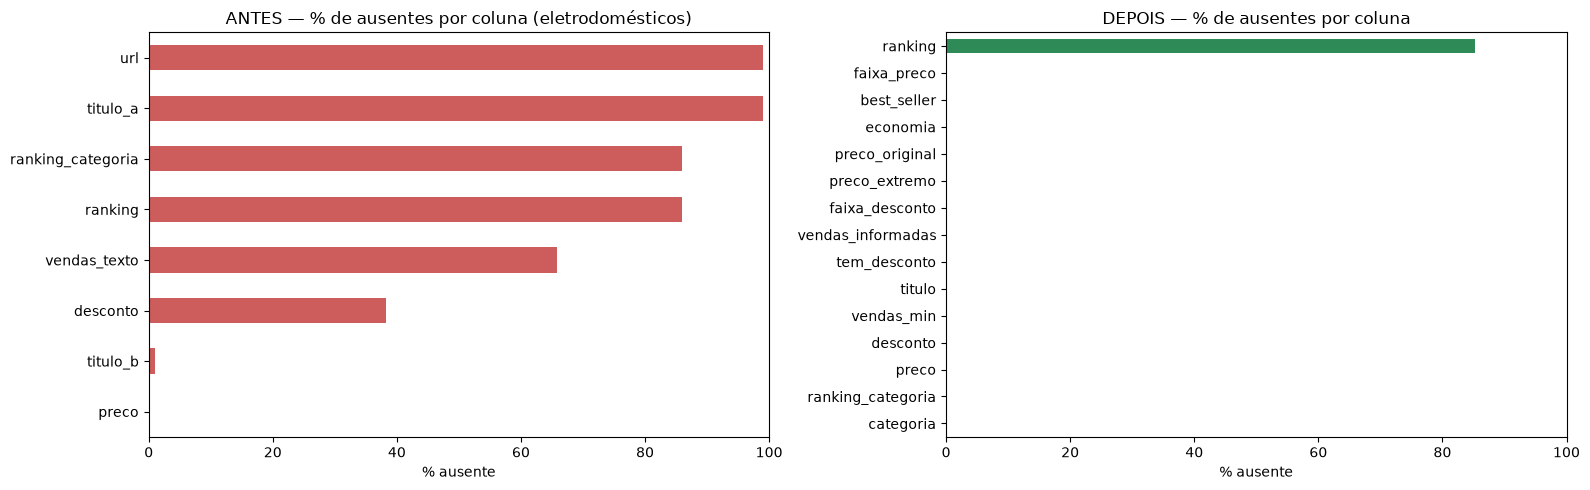

In [17]:
# VISUALIZAÇÕES
# 1) % de ausentes por coluna, antes x depois (eletrodomésticos)
nome = 'us-shein-appliances-3987.csv'
antes = (brutos[nome].rename(columns=NOMES_COLUNAS).isna().mean() * 100)
depois = (limpos[nome].isna().mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
antes.sort_values().plot.barh(ax=axes[0], color='indianred')
axes[0].set_title('ANTES — % de ausentes por coluna (eletrodomésticos)')
axes[0].set_xlim(0, 100)
depois.sort_values().plot.barh(ax=axes[1], color='seagreen')
axes[1].set_title('DEPOIS — % de ausentes por coluna')
axes[1].set_xlim(0, 100)
for ax in axes:
    ax.set_xlabel('% ausente')
plt.tight_layout()
plt.show()

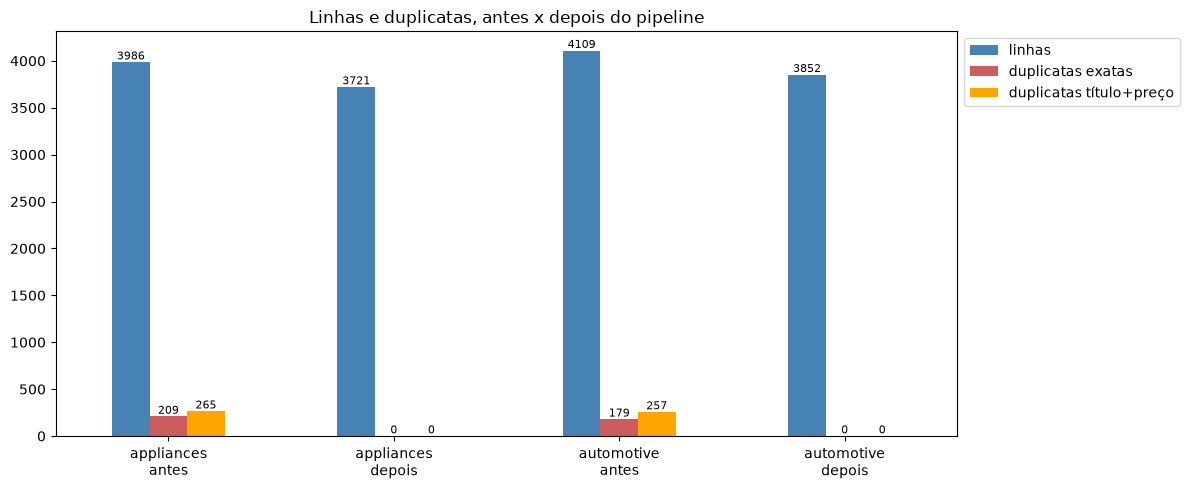

In [18]:
# 2) linhas e duplicatas antes x depois
plot = antes_depois[['linhas', 'duplicatas exatas', 'duplicatas título+preço']].astype(int)
plot.index = [f"{n.replace('us-shein-', '').split('-')[0]}\n{m}" for n, m in plot.index]
ax = plot.plot.bar(figsize=(12, 5), color=['steelblue', 'indianred', 'orange'], rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8)
ax.set_title('Linhas e duplicatas, antes x depois do pipeline')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

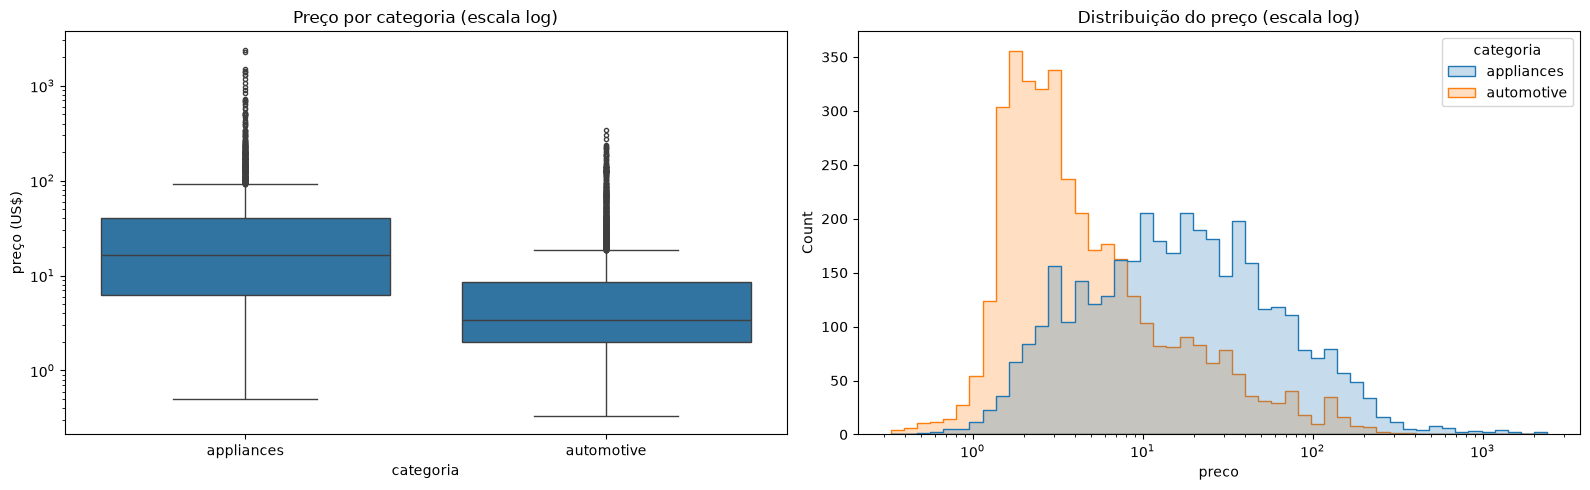

categoria
appliances     18
automotive    109
Name: produtos com preço extremo, dtype: int64

       categoria  \
3253  appliances   
2737  appliances   
3714  appliances   
1399  appliances   
3712  appliances   
3128  appliances   

                                                                               titulo  \
3253  BOSSCARE Full Body Zero Gravity 4D Massage Chair, 2024 APP & AI Control Mass...   
2737  VEVOR Commercial Ice Cream Machine, 20-25L/H Yield, 2400W 1-Flavor Hard Serv...   
3714  BOSSCARE 3D Full Body SL Track Massage Chair, APP Control, Body Scanning, Ze...   
1399  VEVOR Slushy Machine, 30L Slushie Machine For Home, 1250W Commercial Slushy ...   
3712  BOSSCARE 3D Full Body SL Track Massage Chair, APP Control, Body Scanning, Ze...   
3128                         Bosch NGM5658UC 36 Inch Stainless 500 Series Gas Cooktop   

        preco  
3253  2399.99  
2737  2254.99  
3714  1499.99  
1399  1430.99  
3712  1399.99  
3128  1398.00  


In [19]:
# 3) o preço agora é número: distribuição por categoria (escala log) com os extremos marcados
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df_final, x='categoria', y='preco', ax=axes[0], flierprops={'markersize': 3})
axes[0].set_yscale('log')
axes[0].set_title('Preço por categoria (escala log)')
axes[0].set_ylabel('preço (US$)')

sns.histplot(data=df_final, x='preco', hue='categoria', log_scale=True, bins=50, ax=axes[1], element='step')
axes[1].set_title('Distribuição do preço (escala log)')
plt.tight_layout()
plt.show()

print(df_final.groupby('categoria')['preco_extremo'].sum().rename('produtos com preço extremo'))
print()
print(df_final[df_final['preco_extremo'] == 1].nlargest(6, 'preco')[['categoria', 'titulo', 'preco']])

### Respondendo à pergunta de negócio

In [20]:
# desconto x vendas
resumo_desc = (df_final.groupby(['categoria', 'faixa_desconto'], observed=True)
               .agg(produtos=('titulo', 'size'), vendas_mediana=('vendas_min', 'median'),
                    vendas_media=('vendas_min', 'mean'), pct_com_vendas_informadas=('vendas_informadas', 'mean'))
               .round(2))
resumo_desc

produtos  vendas_mediana  vendas_media  \
categoria  faixa_desconto                                           
appliances sem desconto        1487             0.0        132.21   
           1-20%                821             0.0        179.66   
           21-40%               830             0.0         28.22   
           41-60%               444             0.0         69.93   
           >60%                 139             0.0        105.83   
automotive sem desconto        2570           100.0        299.83   
           1-20%                431            60.0        305.59   
           21-40%               532            30.0        164.61   
           41-60%               257            60.0        198.52   
           >60%                  62           100.0        271.61   

                           pct_com_vendas_informadas  
categoria  faixa_desconto                             
appliances sem desconto                         0.39  
           1-20%                                0.48  
           21-40%                               0.22  
           41-60%                               0.28  
           >60%                                 0.21  
automotive sem desconto                         0.72  
           1-20%                                0.69  
           21-40%                               0.61  
           41-60%                               0.68  
           >60%                                 0.85

In [21]:
# preço x vendas
resumo_preco = (df_final.groupby(['categoria', 'faixa_preco'], observed=True)
                .agg(produtos=('titulo', 'size'), vendas_mediana=('vendas_min', 'median'),
                     vendas_media=('vendas_min', 'mean'), vendas_total=('vendas_min', 'sum'))
                .round(1))
resumo_preco

produtos  vendas_mediana  vendas_media  vendas_total
categoria  faixa_preco                                                      
appliances até $5            784            20.0         305.4      239420.0
           $5-10             571            10.0         150.4       85880.0
           $10-25            977             0.0          78.9       77120.0
           $25-50            644             0.0          12.2        7860.0
           $50-100           410             0.0           6.1        2500.0
           > $100            335             0.0           1.5         490.0
automotive até $5           2404           100.0         364.3      875700.0
           $5-10             598            50.0         207.5      124070.0
           $10-25            441            10.0         106.8       47120.0
           $25-50            221             0.0          43.0        9500.0
           $50-100           108             0.0          11.9        1280.0
           > $100             80             0.0           0.5          40.0

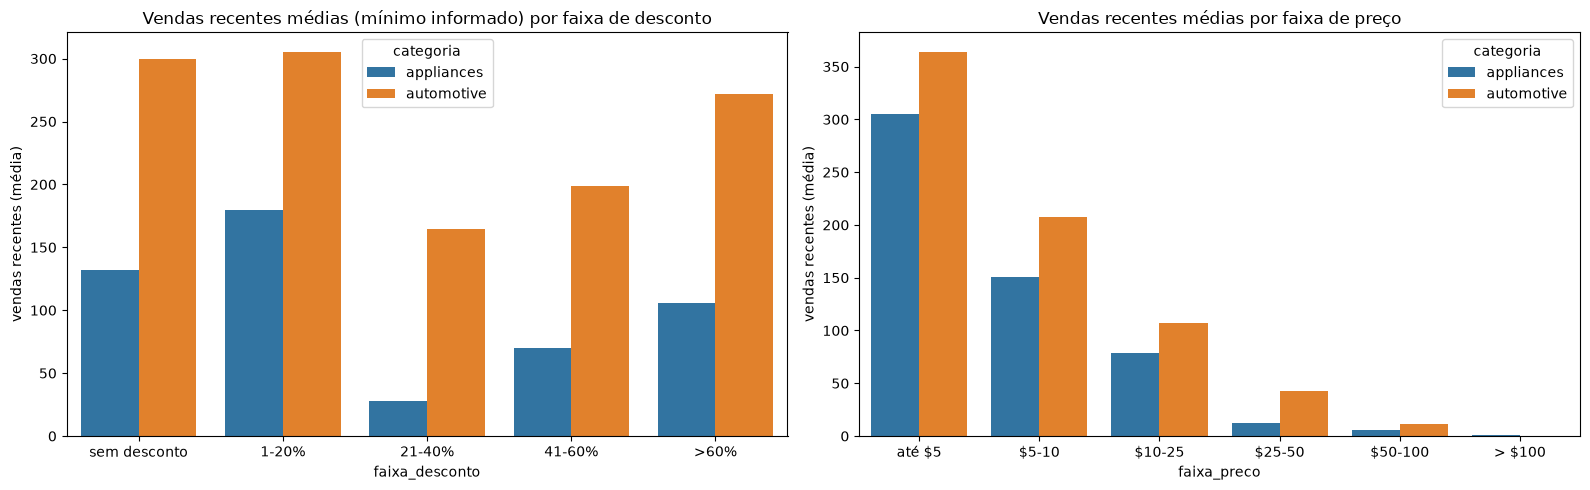

Correlação de Spearman entre desconto e vendas, por categoria:
categoria
appliances   -0.149
automotive   -0.086
Name: desconto, dtype: float64


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=df_final, x='faixa_desconto', y='vendas_min', hue='categoria', estimator='mean', errorbar=None, ax=axes[0])
axes[0].set_title('Vendas recentes médias (mínimo informado) por faixa de desconto')
axes[0].set_ylabel('vendas recentes (média)')
sns.barplot(data=df_final, x='faixa_preco', y='vendas_min', hue='categoria', estimator='mean', errorbar=None, ax=axes[1])
axes[1].set_title('Vendas recentes médias por faixa de preço')
axes[1].set_ylabel('vendas recentes (média)')
plt.tight_layout()
plt.show()

print('Correlação de Spearman entre desconto e vendas, por categoria:')
print(df_final.groupby('categoria')[['desconto', 'vendas_min']].corr(method='spearman').xs('vendas_min', level=1)['desconto'].round(3))

In [23]:
# experimento para a reflexão: a ORDEM das etapas muda o resultado?
d = organizar_colunas(brutos['us-shein-appliances-3987.csv'], 'appliances')
d = padronizar_textos(corrigir_tipos(d))

# (a) imputar vendas pela MÉDIA antes de tratar outliers / duplicatas
media_com_tudo = d['vendas_min'].mean()
# (b) tratar outliers primeiro (capping no IQR) e só depois calcular a média para imputar
v = d['vendas_min']
q1, q3 = v.quantile([.25, .75])
media_pos_capping = v.clip(upper=q3 + 1.5 * (q3 - q1)).mean()
# (c) remover duplicatas primeiro
media_sem_dup = d.drop_duplicates()['vendas_min'].mean()

print(f'Valor que seria imputado nas {v.isna().sum()} linhas sem vendas:')
print(f'   média com outliers e duplicatas : {media_com_tudo:,.1f}')
print(f'   média depois do capping         : {media_pos_capping:,.1f}')
print(f'   média depois de tirar duplicatas: {media_sem_dup:,.1f}')

# e o contrário: limites de outlier do DESCONTO calculados antes x depois de preencher ausentes com 0
desc = d['desconto']
def lim(s):
    q1, q3 = s.quantile([.25, .75]); return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print()
print('Limites IQR do desconto ANTES de preencher ausentes:', [round(x, 1) for x in lim(desc.dropna())])
print('Limites IQR do desconto DEPOIS de preencher com 0  :', [round(x, 1) for x in lim(desc.fillna(0))])

Valor que seria imputado nas 2625 linhas sem vendas:
   média com outliers e duplicatas : 328.9
   média depois do capping         : 142.3
   média depois de tirar duplicatas: 329.8

Limites IQR do desconto ANTES de preencher ausentes: [-39.5, 92.5]
Limites IQR do desconto DEPOIS de preencher com 0  : [-52.5, 87.5]


In [24]:
# salvando a base limpa
df_final.to_csv('shein_limpo.csv', index=False)
print('Arquivo salvo: shein_limpo.csv', df_final.shape)

Arquivo salvo: shein_limpo.csv (7573, 15)


## Relatório e respostas às perguntas de reflexão

### Relatório das decisões

**Estrutura e tipos**
- Juntei as duas colunas de título (`goods-title-link--jump` nas 40 primeiras linhas, `goods-title-link` nas demais). Provavelmente a primeira "página" do site foi raspada com uma classe HTML diferente. Juntas, não falta nenhum título.
- Removi a URL, que só existia para essas 40 linhas.
- Converti preço (tirando `$` **e** a vírgula de milhar), desconto (tirando `-` e `%`), vendas (interpretando o `k` como mil) e posição no ranking.

**Textos**
- Tirei espaços extras e repetidos dos títulos e criei uma chave em minúsculas só para comparar. Mantive o título original "bonito" na base final.
- Tirei o "in " do começo da subcategoria do ranking.

**Duplicatas**
- Removi as exatas e depois as que têm o mesmo título padronizado e o mesmo preço. Quando havia mais de uma, fiquei com a que mostrava mais vendas.
- **Não** juntei produtos com o mesmo título e preços diferentes: podem ser variações (tamanho, cor, quantidade de peças) e o preço diferente importa para a pergunta.

**Ausentes**
- Desconto ausente → 0, com a coluna `tem_desconto`. No site, o selo só aparece quando existe desconto.
- Vendas ausentes → 0, com a coluna `vendas_informadas`. A coluna representa "pelo menos X vendas", então 0 é um limite inferior honesto (o site só mostra o selo acima de um mínimo).
- Ranking ausente → "Fora do ranking" na subcategoria; a posição fica vazia.

**Outliers**
- Não removi nenhum preço. Os preços altos são produtos reais: nos eletrodomésticos, cadeiras de massagem, máquinas comerciais VEVOR e cooktops Bosch/Frigidaire (18 marcados); no automotivo, centrais multimídia, compressores de pneu, amplificadores e peças específicas para BMW/Mercedes (109 marcados, acima de ~$77). Para a pergunta, eles caem na faixa "> $100" e não distorcem nada. Apenas marquei com `preco_extremo`, usando o IQR no **log** do preço, porque no preço original o IQR marcaria uma parte enorme da base.

**Features criadas:** `preco_original`, `economia`, `faixa_desconto`, `faixa_preco`, `tem_desconto`, `vendas_informadas`, `best_seller`, `preco_extremo` e `categoria`.

**O que os dados mostram (resposta preliminar à pergunta):** a relação entre desconto e vendas é **fraca e até levemente negativa** nas duas categorias (Spearman de -0,15 em eletrodomésticos e -0,09 em automotivo). No automotivo, por exemplo, a mediana de vendas dos produtos **sem desconto** (100) é maior que a dos produtos com 21-40% (30). Desconto maior não garante mais vendas; talvez os produtos que já vendem bem nem precisem de desconto. O que aparece com mais clareza é o preço: nas duas categorias, os produtos mais vendidos se concentram na faixa **até $5** (no automotivo, essa faixa sozinha soma mais de 875 mil vendas "mínimas", contra 40 na faixa acima de $100), e as vendas caem rápido a partir de $10-25. Uma ressalva importante: a coluna de vendas é um "mínimo" arredondado e só aparece para parte dos produtos, então isso é uma tendência, não uma medida exata.

### Reflexão

**1. Qual problema foi o mais difícil de perceber? Por que ele passaria despercebido numa análise rápida?**

Para mim foram dois problemas parecidos, ambos na conversão de texto para número: o **separador de milhar no preço** (`$1,430.99`) e o **"k" nas vendas** (`1.3k+ sold recently`).

Eles são difíceis de perceber porque a conversão "rápida" **não dá erro**. Com `pd.to_numeric(..., errors='coerce')`, os 13 preços com vírgula viram NaN em silêncio, e como são só 13 de quase 4 mil linhas, ninguém nota no `head()` nem no `describe()`. Só que esses 13 são justamente os produtos mais caros da base, então o problema distorce exatamente a parte que interessa para análise de preço. Já no caso do "k", pegar o primeiro número com uma regex simples transforma "1.3k" em **1**, então o produto mais vendido vira um dos que menos vende, e nada quebra. Só descobri porque fui olhar os valores únicos que **não** seguiam o padrão esperado.

O título dividido em duas colunas também foi traiçoeiro: olhando só a porcentagem de ausentes, a coluna `goods-title-link--jump` parece 99% vazia e "descartável".

**2. A ordem das etapas importa? Dê um exemplo.**

Importa, e o experimento mais acima mostra com números:
- Se eu imputasse as vendas ausentes pela **média** antes de tratar outliers, o valor colocado nas 2.625 linhas sem vendas (eletrodomésticos) seria **328,9**. Se eu fizesse o capping antes, seria **142,3**, menos da metade. Alguns produtos com "5.6k+" ou "10k+" puxam a média para cima. A ordem muda o valor que vai para mais de 2 mil linhas.
- O contrário também acontece: os limites de outlier do **desconto** calculados antes de preencher os ausentes vão de -39,5% a 92,5%; depois de colocar 0 em quem não tem desconto, o limite de cima cai para 87,5%. Ou seja, o produto com 88% de desconto só vira "outlier" por causa da ordem em que fiz as coisas.
- Esperava que tirar as duplicatas antes também mudasse bastante a média, mas aqui quase não mudou (328,9 para 329,8). Achei que valia registrar: nem toda ordem faz diferença em todo dataset, mas a gente só sabe testando.

Por isso escolhi a ordem tipos → textos → duplicatas → ausentes → outliers. Mesmo assim, é uma escolha: dependendo da imputação usada, poderia fazer sentido tratar outliers antes.

**3. Se a pergunta de negócio fosse outra, qual decisão eu mudaria?**

Algumas:
- Se a pergunta fosse **"quanto custa, em média, um produto de cada categoria no catálogo?"**, eu trataria os outliers de preço de outro jeito (usaria a mediana ou separaria os produtos comerciais/profissionais), e deixaria de lado a coluna de vendas, então não precisaria imputar 0 nela.
- Se a pergunta fosse sobre **variedade de produtos/variações**, eu não removeria as duplicatas por título+preço; talvez até mantivesse os registros com preços diferentes como variantes distintas.
- Se a pergunta fosse **"o que faz um produto entrar no ranking de best sellers?"**, o arquivo de automotivo nem serviria (não tem ranking), e os ausentes de `ranking` virariam a variável alvo (0 = não é best seller), em vez de ficarem vazios.
- E se a análise fosse sobre **o efeito do desconto**, eu não colocaria 0 no desconto ausente sem confirmar com o time de negócio que "sem selo" realmente significa "sem desconto", porque essa suposição mexe diretamente na resposta.